# Pronóstico semanal de compras: Evaluación

Predecir el importe de compras positivas de la próxima semana.

MAE y RMSE a un paso. Cada semana posterior usa observaciones reales previas; no es pronóstico multisemana desde un origen. No mide ventas netas ni beneficios; histórico corto para estacionalidad anual.

Consulta la [metodología](../docs/metodologia.md). Los reportes corresponden a la última ejecución de cada etapa.


In [1]:
from pathlib import Path
import os
import sys
from IPython.display import Markdown, display
def _buscar_proyecto(paquete):
    """Encuentra el paquete propio desde el proyecto, tema o portafolio."""
    for base in (Path.cwd().resolve(), *Path.cwd().resolve().parents):
        if (base / "src" / paquete).is_dir():
            return base
        for container in (base, base / "Analisis"):
            for pattern in (f"*/src/{paquete}", f"*/*/src/{paquete}"):
                for source in sorted(container.glob(pattern)):
                    parts = source.relative_to(container).parts
                    if "back" in parts or any(p.startswith(".") for p in parts):
                        continue
                    candidate = source.parent.parent
                    if (candidate / "pyproject.toml").is_file():
                        return candidate
    return None

PROJECT_ROOT = _buscar_proyecto("retail_sales_forecasting")
if PROJECT_ROOT is None:
    raise RuntimeError("Abre el notebook desde el proyecto, notebooks o su carpeta contenedora.")
os.chdir(PROJECT_ROOT)
if str(PROJECT_ROOT / "src") not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / "src"))
for folder in ("data/raw", "data/intermediate", "data/processed", "data/output", "models", "reports"):
    (PROJECT_ROOT / folder).mkdir(parents=True, exist_ok=True)
from retail_sales_forecasting.alerts import configurar_notebook, mostrar_alertas
configurar_notebook()


# Pronóstico semanal de compras: evaluacion

El modelo **no mejora** el MAE del baseline: **220296.11** frente a **59811.14**, en **10 semanas de test**. El protocolo es a un paso; incorpora ventas reales previas al avanzar. Mide compras positivas, no ventas netas ni beneficios. Un único bloque corto no permite concluir robustez entre temporadas.


,baseline,modelo
casos,10.000000,10.000000
mae,59811.139900,220296.107902
rmse,71058.636196,232499.013567


,timestamp,value,prediccion_modelo,prediccion_baseline
0,2011-10-02,211446.801,133292.260437,338294.081
1,2011-10-09,319084.770,85134.980556,211446.801
2,2011-10-16,228037.070,94097.355316,319084.770
3,2011-10-23,275970.350,83857.941842,228037.070
4,2011-10-30,259312.530,89333.604014,275970.350
5,2011-11-06,300643.080,89367.713888,259312.530
6,2011-11-13,368996.320,85089.980290,300643.080
7,2011-11-20,387064.650,72683.869154,368996.320
8,2011-11-27,315114.060,40308.517341,387064.650
9,2011-12-04,323398.700,12941.029141,315114.060


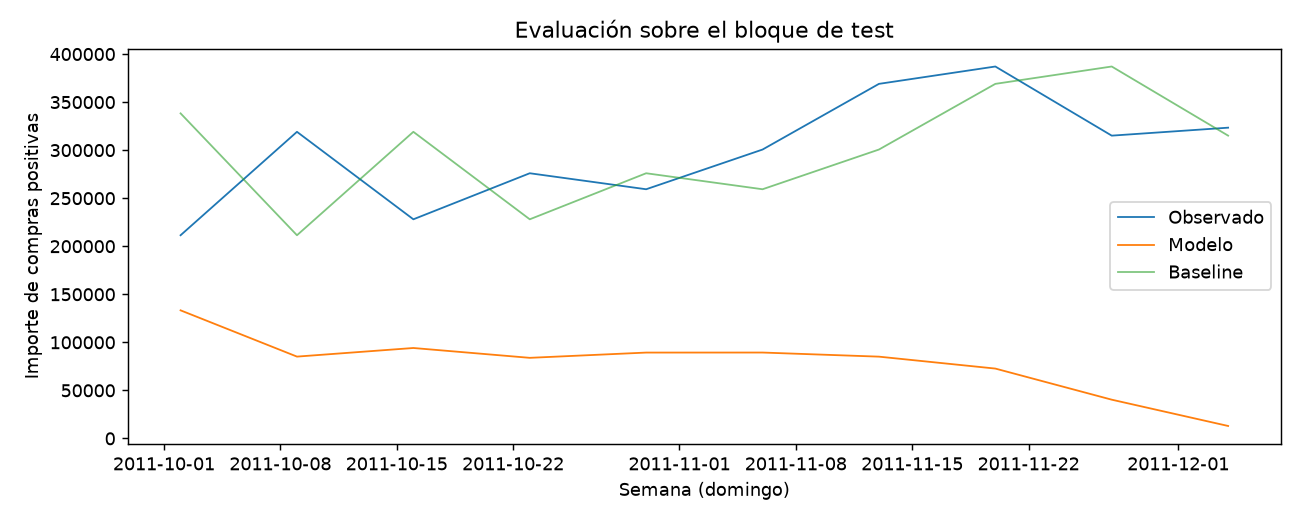

In [2]:
from retail_sales_forecasting.flow import run_stage
metricas, comentario = run_stage(PROJECT_ROOT, "evaluacion")
display(Markdown(comentario))
from retail_sales_forecasting.presentation import display_evaluation
display_evaluation(PROJECT_ROOT, metricas)


## Alertas

Avisos agrupados con descripción y acción sugerida. Los errores no se ocultan; no registrar warnings no garantiza que el análisis sea válido.

In [ ]:
mostrar_alertas(PROJECT_ROOT / "reports/alertas/05_evaluacion.json")
from retail_sales_forecasting.informe import generar_informe
generar_informe(PROJECT_ROOT)
